# SC04 Step 3 - Adaptive Traffic Signal Fuzzy Logic Controller

This notebook implements and evaluates the **Mamdani Fuzzy Logic Controller** for **SC04: Adaptive Traffic Signal Optimization System** (two-phase junction: `NS` vs `EW`).

- **Honesty rule:** All 10,000 scenarios in `data/generated/traffic_scenarios_10000.csv` are *generated* scenarios from Step 2, not real traffic observations.
- **Safety rule:** Invalid rows are always rejected before inference; active emergency directions override normal priority; green duration stays inside `[10 s, 60 s]`.

In [1]:
from pathlib import Path
import json
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from step3_fuzzy_controller import (
    FEATURES,
    OUTPUTS,
    RANDOM_SEED,
    build_fuzzy_systems,
    compute_reference_phase,
    load_split,
    metric_row,
    plot_confusion_matrix,
    plot_control_surface_and_distributions,
    plot_membership_functions,
    predict_fuzzy,
    prepare_splits,
    verify_invalid_rejection,
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "data" / "reports"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results" / "step3"

for folder in (DATA_DIR, REPORT_DIR, MODEL_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Features:", FEATURES)
print("Outputs:", OUTPUTS)

Project folder: c:\Users\ankus\Desktop\New folder
Features: ['queue_ns', 'queue_ew', 'density_ns_pct', 'density_ew_pct', 'max_wait_ns_sec', 'max_wait_ew_sec', 'emergency_direction']
Outputs: ['next_phase', 'green_duration_sec']


## 1. Load and Validate Stratified Step 2 Splits
We split the 10,000 validated Step 2 scenarios reproducibly (`RANDOM_SEED = 42`, stratified by `scenario_type`) into `train.csv` (70%), `validation.csv` (15%), and `test.csv` (15%). Each split is checked by `validate_data.check_dataframe` before use.

In [2]:
prepare_splits()
train_data = load_split("train")
validation_data = load_split("validation")
test_data = load_split("test")

for name, frame in [("Train", train_data), ("Validation", validation_data), ("Test", test_data)]:
    print(f"\n{name}: {frame.shape[0]} rows, {frame.shape[1]} columns")
    print(frame["scenario_type"].value_counts(normalize=True).round(3).to_string())

display(train_data.head())


Train: 7000 rows, 9 columns
scenario_type
normal       0.50
stress       0.15
difficult    0.15
boundary     0.15
emergency    0.05

Validation: 1500 rows, 9 columns
scenario_type
normal       0.50
difficult    0.15
stress       0.15
boundary     0.15
emergency    0.05

Test: 1500 rows, 9 columns
scenario_type
normal       0.50
difficult    0.15
boundary     0.15
stress       0.15
emergency    0.05


,state_id,queue_ns,queue_ew,density_ns_pct,density_ew_pct,max_wait_ns_sec,max_wait_ew_sec,emergency_direction,scenario_type
0,SCN-01111,14,15,28.3,33.6,56,93,none,normal
1,SCN-09342,0,3,0.0,7.3,0,40,none,normal
2,SCN-00953,11,0,13.8,3.0,38,0,none,normal
3,SCN-00612,24,18,45.3,33.8,58,89,none,normal
4,SCN-03533,4,47,10.4,78.2,299,236,none,stress


## 2. Build the Mamdani Fuzzy Inference System (FIS)
We construct a symmetric Mamdani FIS with 27 complete IF-THEN rules (`3 queue × 3 density × 3 wait`) for both **Approach Urgency (`0-100`)** and **Green Duration (`10-60 s`)**, plus Rule 4 emergency safety override.

Architecture: 7 traffic inputs -> symmetric Mamdani Urgency & Green FIS (27 rules) + emergency override -> 2 outputs
Sample rules:
 - IF queue=low AND density=low AND wait=short THEN urgency=very_low, green=very_short
 - IF queue=low AND density=low AND wait=moderate THEN urgency=low, green=very_short
 - IF queue=low AND density=low AND wait=long THEN urgency=high, green=short
 - IF queue=low AND density=medium AND wait=short THEN urgency=very_low, green=very_short
 - IF queue=low AND density=medium AND wait=moderate THEN urgency=low, green=short


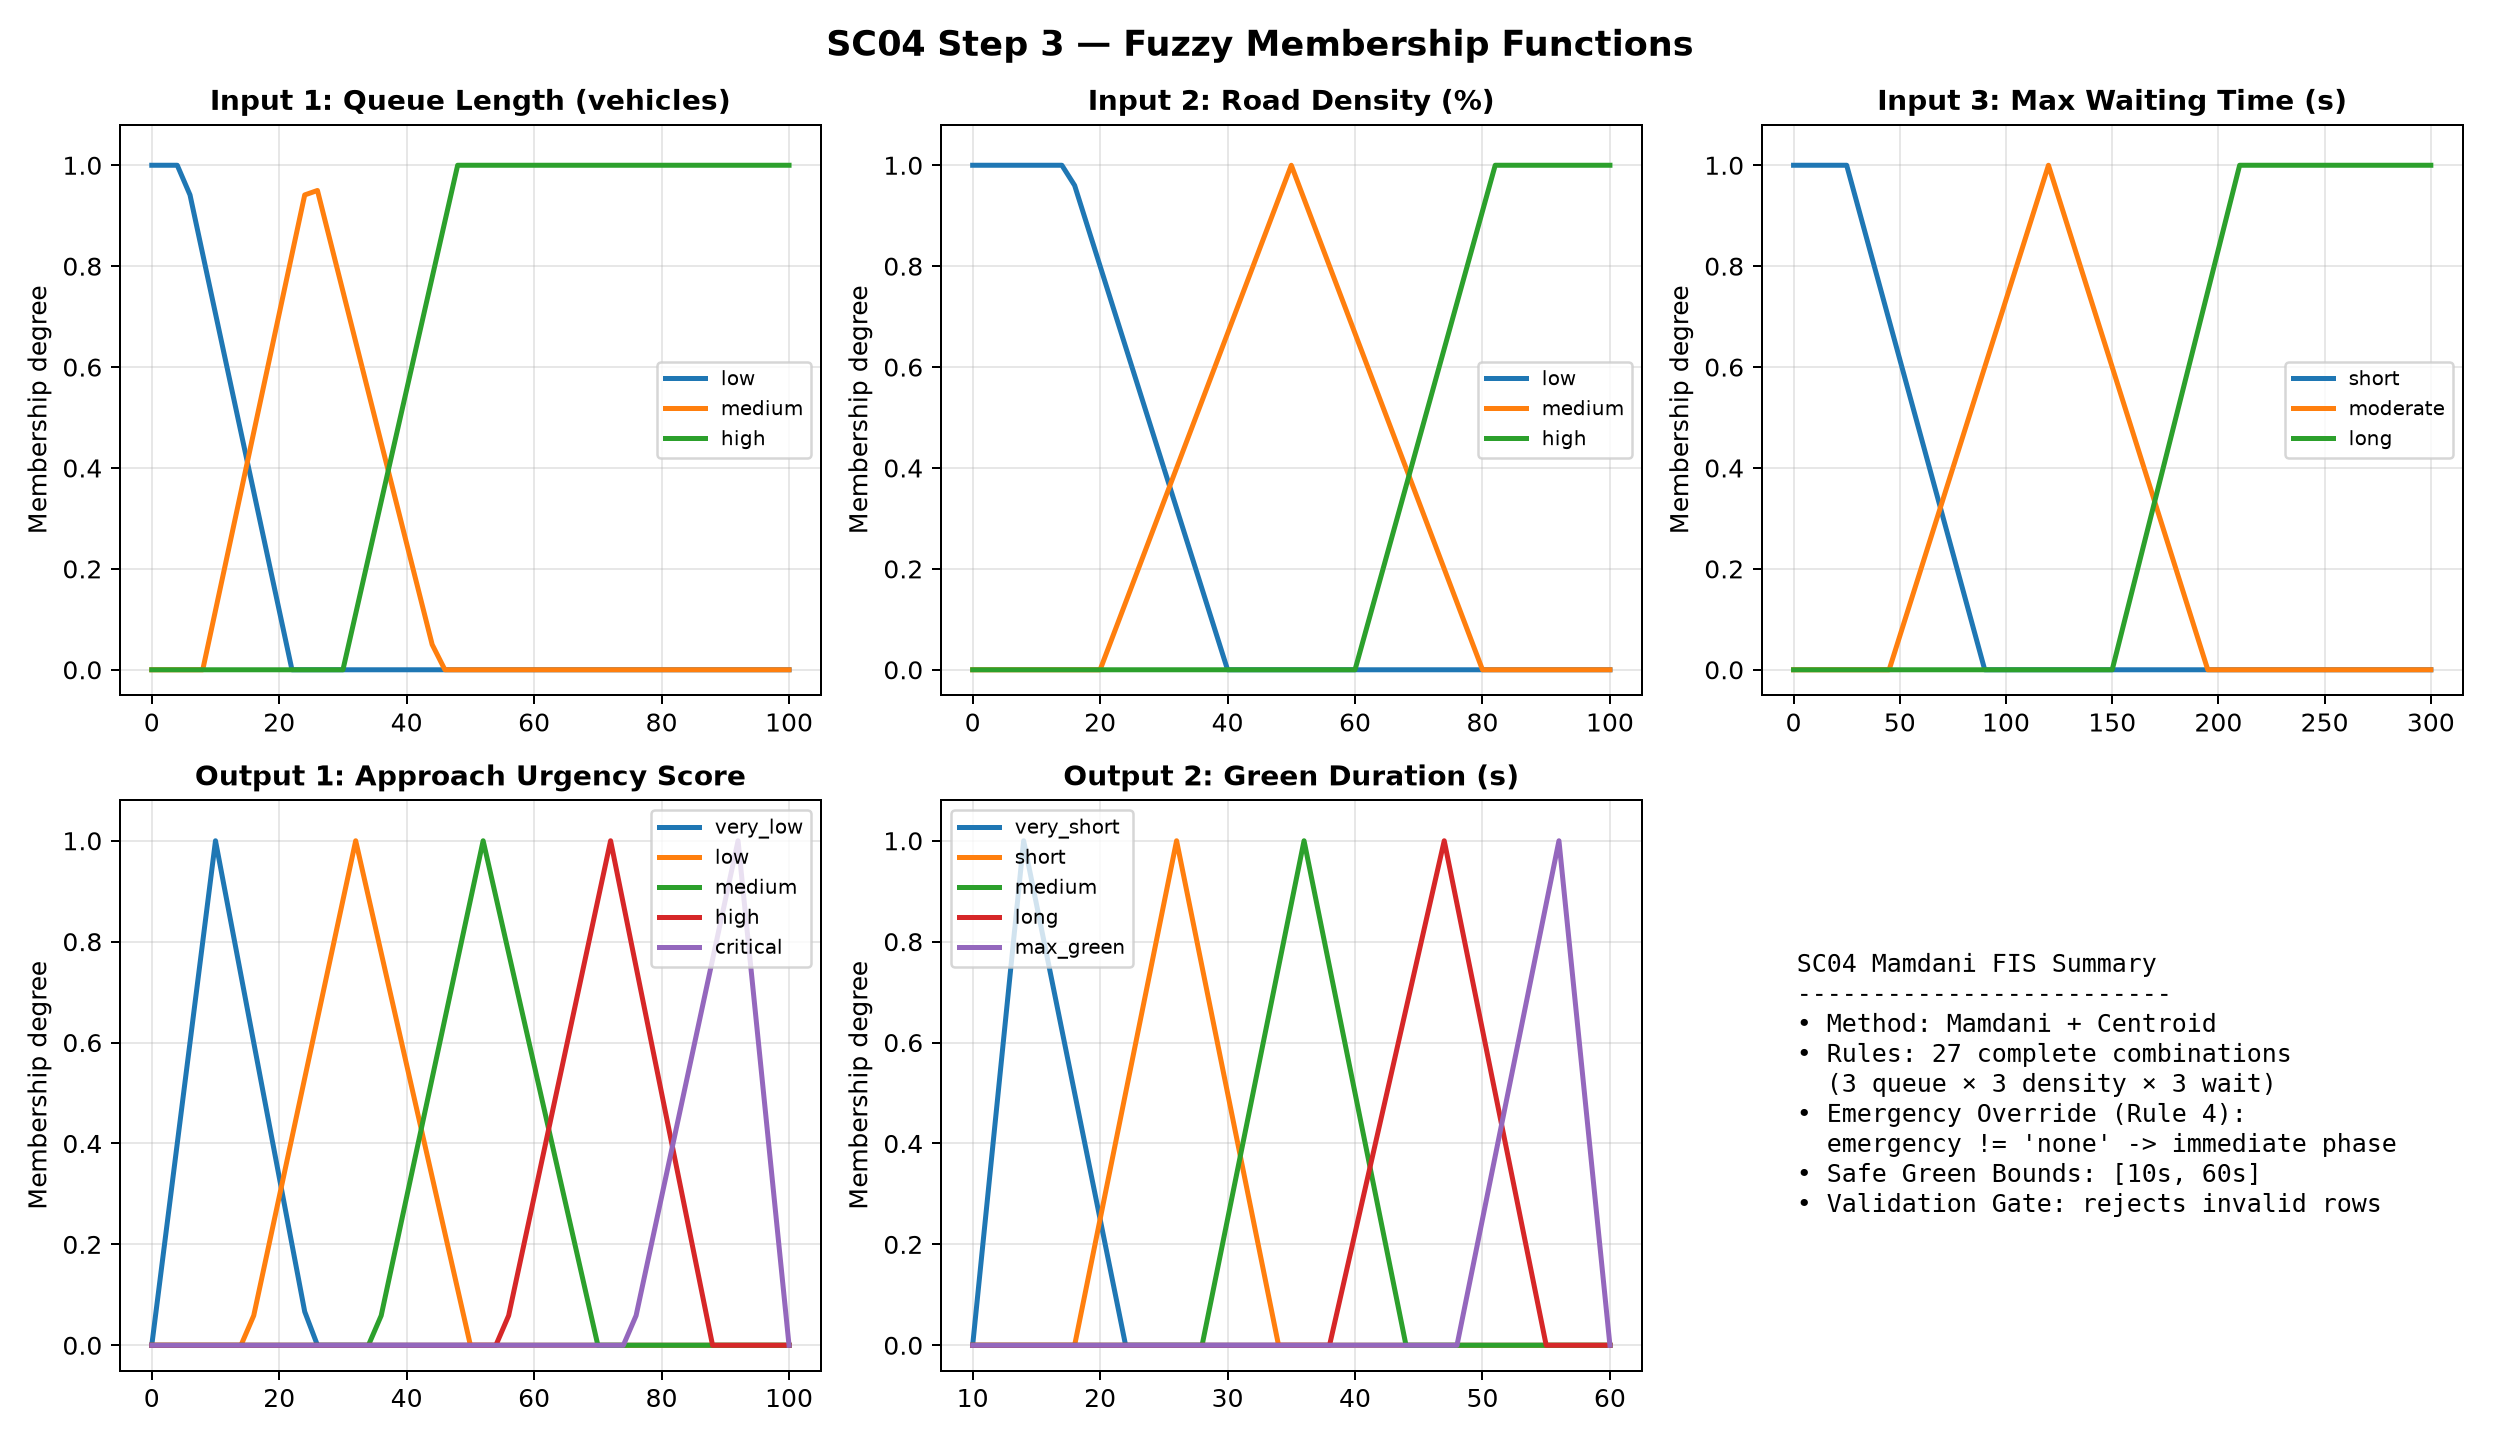

In [3]:
fuzzy_bundle = build_fuzzy_systems()
print("Architecture: 7 traffic inputs -> symmetric Mamdani Urgency & Green FIS (27 rules) + emergency override -> 2 outputs")
print("Sample rules:")
for rule_text in fuzzy_bundle["rule_descriptions"][:5]:
    print(" -", rule_text)

mf_path = RESULTS_DIR / "step3_fuzzy_membership_functions.png"
plot_membership_functions(fuzzy_bundle, mf_path)

## 3. Evaluate on Validation Split
We first run the fuzzy controller on `validation.csv` and check phase alignment against the transparent domain-priority reference as well as emergency and green-duration safety compliance.

In [4]:
val_pred = predict_fuzzy(validation_data, fuzzy_bundle)
val_ref = compute_reference_phase(validation_data)
val_pred["reference_phase"] = val_ref

val_metrics = metric_row(val_ref, val_pred["fuzzy_next_phase"].to_numpy(), val_pred, "validation")
display(pd.DataFrame([val_metrics]))

,split,rows,accuracy,precision_ns,recall_ns,f1_score_ns,f1_macro,emergency_compliance,green_bounds_compliance,mean_green_sec
0,validation,1500,0.8827,0.8687,0.9012,0.8847,0.8826,1.0,1.0,33.23


## 4. Final Evaluation on Held-Out Test Split
We evaluate the held-out `test.csv` split once without tuning on test data, inspect classification reports for `NS` and `EW`, and inspect green-duration adaptation across scenario types.


Validation classification report:
              precision    recall  f1-score   support

          NS       0.87      0.90      0.88       749
          EW       0.90      0.86      0.88       751

    accuracy                           0.88      1500
   macro avg       0.88      0.88      0.88      1500
weighted avg       0.88      0.88      0.88      1500

Test classification report:
              precision    recall  f1-score   support

          NS       0.88      0.89      0.89       779
          EW       0.88      0.87      0.88       721

    accuracy                           0.88      1500
   macro avg       0.88      0.88      0.88      1500
weighted avg       0.88      0.88      0.88      1500

Test green duration by scenario_type:


,split,rows,accuracy,precision_ns,recall_ns,f1_score_ns,f1_macro,emergency_compliance,green_bounds_compliance,mean_green_sec
0,validation,1500,0.8827,0.8687,0.9012,0.8847,0.8826,1.0,1.0,33.23
1,test,1500,0.8827,0.8812,0.8947,0.8879,0.8824,1.0,1.0,33.26


,count,mean,min,max
scenario_type,,,,
boundary,225,35.99,15.33,54.67
difficult,225,30.72,18.80,53.93
emergency,75,28.55,15.33,49.96
normal,750,27.49,15.33,38.28
stress,225,53.86,45.41,54.67


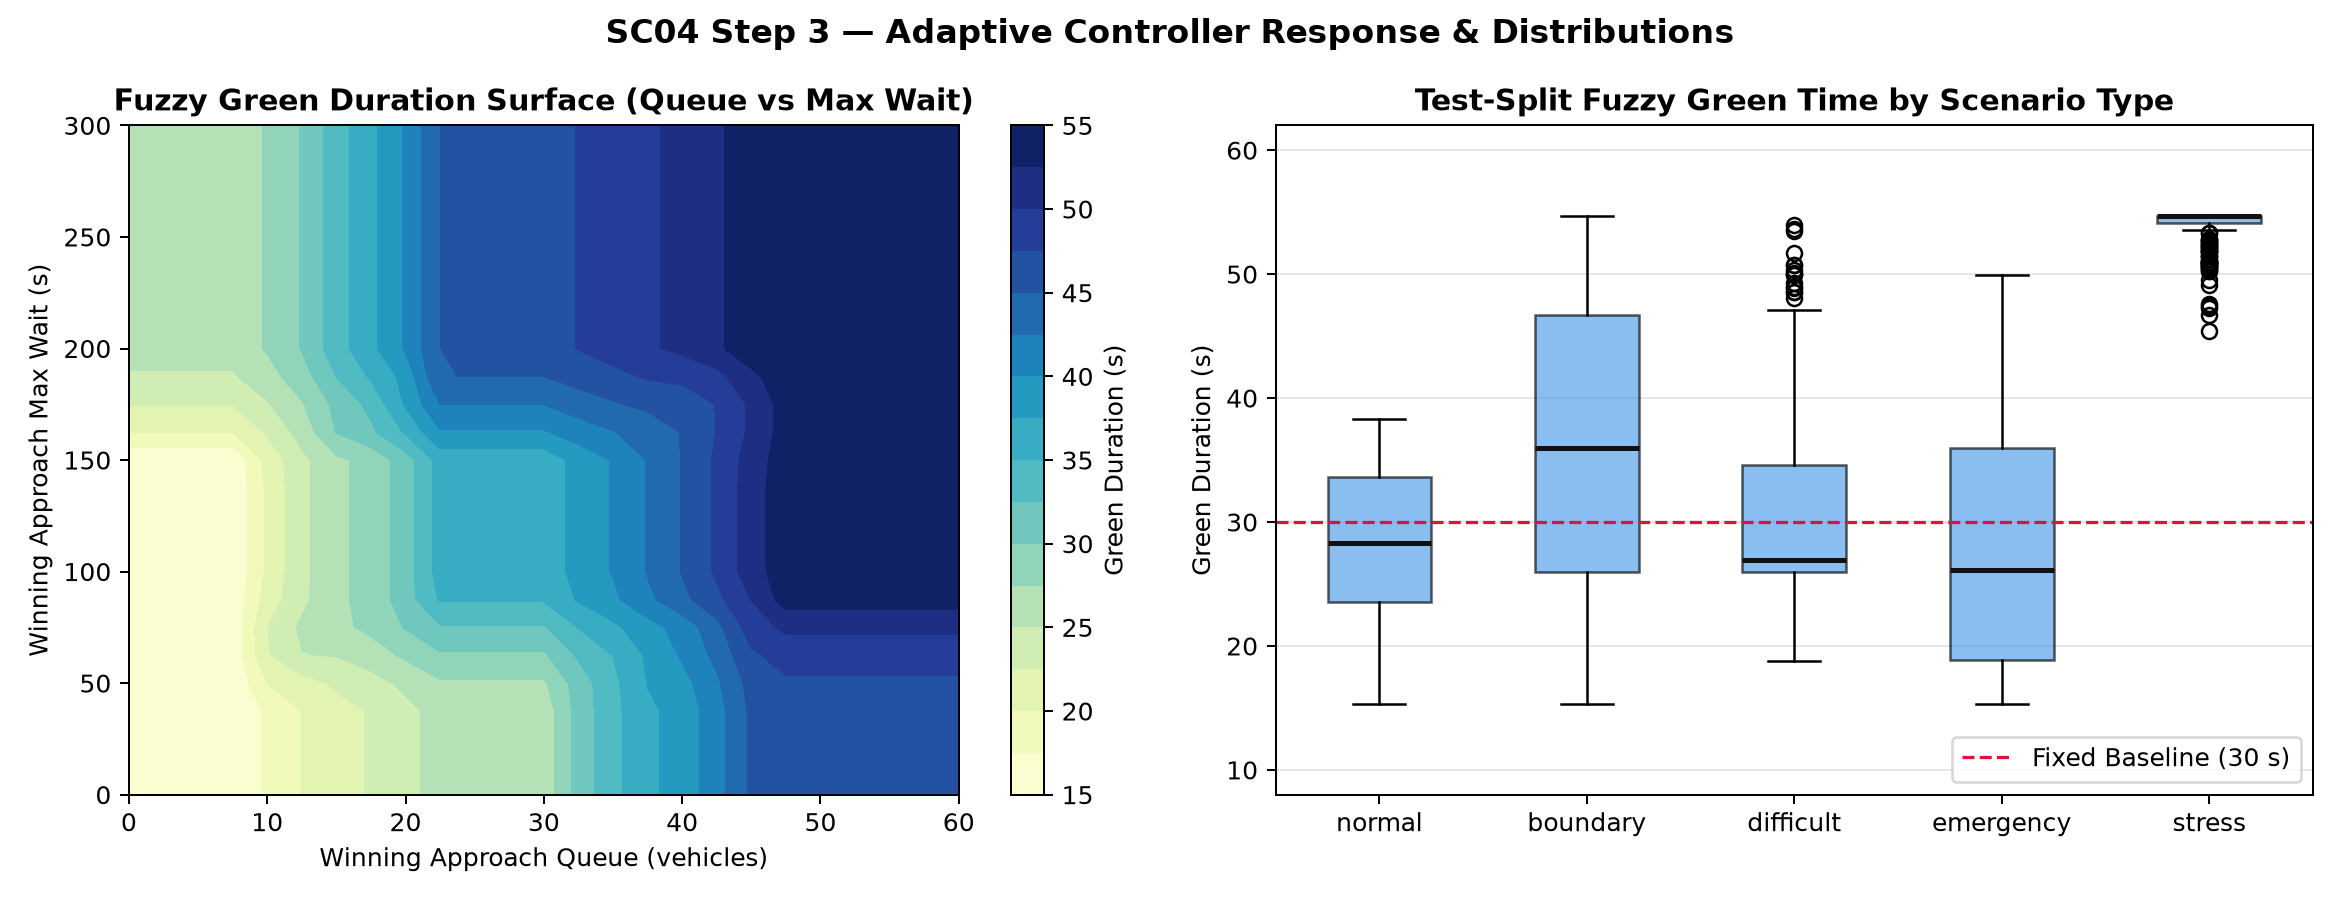

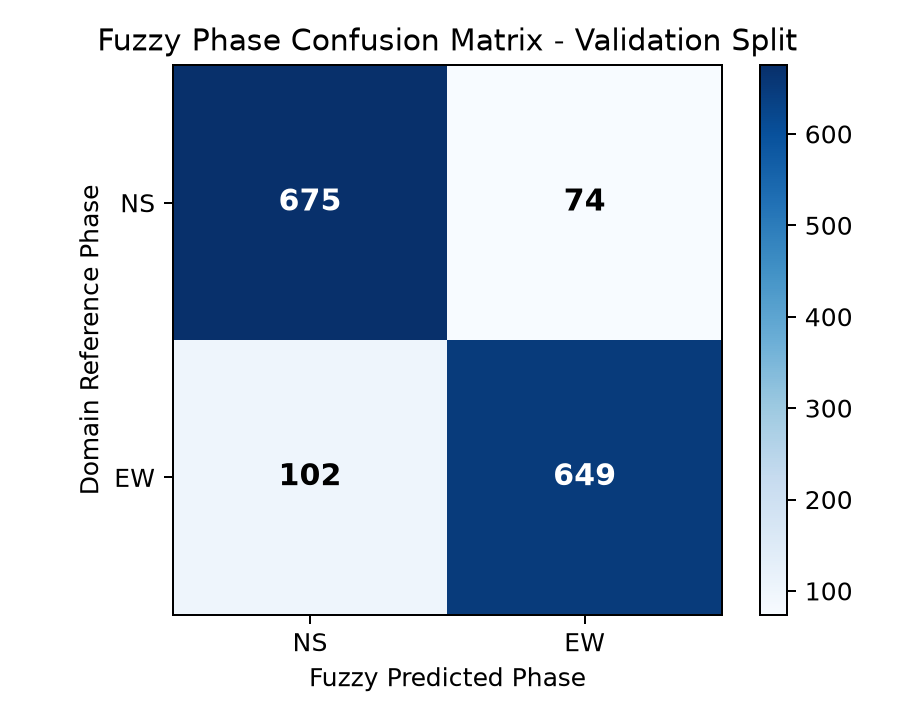

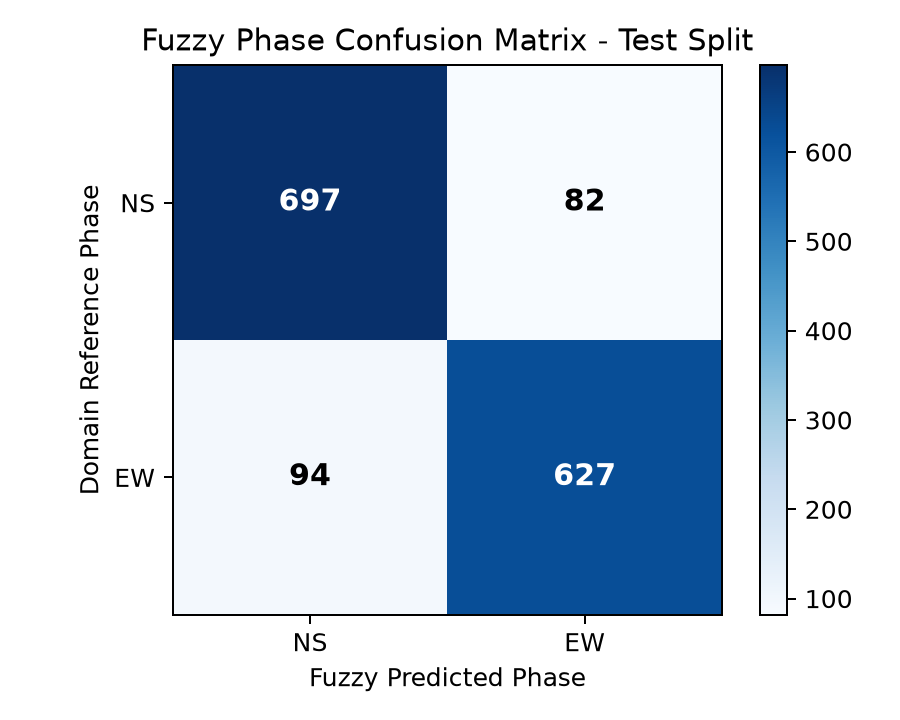

In [5]:
test_pred = predict_fuzzy(test_data, fuzzy_bundle)
test_ref = compute_reference_phase(test_data)
test_pred["reference_phase"] = test_ref

test_metrics = metric_row(test_ref, test_pred["fuzzy_next_phase"].to_numpy(), test_pred, "test")
metrics_df = pd.DataFrame([val_metrics, test_metrics])
display(metrics_df)

print("\nValidation classification report:")
print(classification_report(val_ref, val_pred["fuzzy_next_phase"], labels=["NS", "EW"], zero_division=0))
print("Test classification report:")
print(classification_report(test_ref, test_pred["fuzzy_next_phase"], labels=["NS", "EW"], zero_division=0))

green_summary = test_pred.groupby("scenario_type")["fuzzy_green_duration_sec"].agg(["count", "mean", "min", "max"]).round(2)
print("Test green duration by scenario_type:")
display(green_summary)

surface_path = RESULTS_DIR / "step3_fuzzy_control_surface.png"
val_cm_path = RESULTS_DIR / "step3_validation_confusion_matrix.png"
test_cm_path = RESULTS_DIR / "step3_test_confusion_matrix.png"

plot_control_surface_and_distributions(fuzzy_bundle, test_pred, surface_path)
plot_confusion_matrix(val_ref, val_pred["fuzzy_next_phase"].to_numpy(), "validation", val_cm_path)
plot_confusion_matrix(test_ref, test_pred["fuzzy_next_phase"].to_numpy(), "test", test_cm_path)

## 5. Mandatory Step 1 Sample Cases & Invalid Input Gate
Verify all 20 starter cases (`TRF-001` to `TRF-020`, including the 5 mandatory cases) and confirm invalid rows (`TRF-999` and all 120 Step 2 invalid scenarios) are rejected.

In [6]:
sample_df = pd.read_csv(PROJECT_ROOT / "data" / "sample_input.csv")
sample_pred = predict_fuzzy(sample_df, fuzzy_bundle)
display(sample_pred[["state_id", "queue_ns", "queue_ew", "max_wait_ns_sec", "max_wait_ew_sec", "emergency_direction", "fuzzy_next_phase", "fuzzy_green_duration_sec", "decision_mode"]])

invalid_report = verify_invalid_rejection()
print("Invalid rejection check:", invalid_report)

Invalid rejection check: {'step1_invalid_rejected': True, 'step1_invalid_errors': ['Negative queue length found', 'Density outside 0-100 % found'], 'step2_invalid_total': 120, 'step2_invalid_rejected': 120}


,state_id,queue_ns,queue_ew,max_wait_ns_sec,max_wait_ew_sec,emergency_direction,fuzzy_next_phase,fuzzy_green_duration_sec,decision_mode
0,TRF-001,5,5,25,22,none,NS,15.38,fuzzy_urgency
1,TRF-002,30,6,120,30,none,NS,46.65,fuzzy_urgency
2,TRF-003,4,28,20,115,none,EW,46.66,fuzzy_urgency
3,TRF-004,8,12,190,65,none,NS,29.60,fuzzy_urgency
4,TRF-005,20,20,90,90,EW,EW,34.13,emergency_override
5,TRF-006,12,9,55,40,none,NS,22.64,fuzzy_urgency
6,TRF-007,15,18,70,85,none,EW,31.43,fuzzy_urgency
7,TRF-008,7,10,35,48,none,EW,19.60,fuzzy_urgency
8,TRF-009,22,14,95,60,none,NS,40.27,fuzzy_urgency
9,TRF-010,10,11,50,52,none,EW,21.32,fuzzy_urgency


## 6. Save Controller Artifact, Metadata, and Evidence CSVs

In [7]:
metrics_df.to_csv(REPORT_DIR / "step3_fuzzy_metrics.csv", index=False)
val_pred.to_csv(REPORT_DIR / "step3_validation_predictions.csv", index=False)
test_pred.to_csv(REPORT_DIR / "step3_test_predictions.csv", index=False)
sample_pred.to_csv(REPORT_DIR / "step3_sample_predictions.csv", index=False)

model_payload = {
    "technique": "Mamdani Fuzzy Inference System (scikit-fuzzy)",
    "fuzzy_bundle": fuzzy_bundle,
    "min_green_sec": 10.0,
    "max_green_sec": 60.0,
    "random_seed": RANDOM_SEED,
}
with (MODEL_DIR / "fuzzy_traffic_controller.pkl").open("wb") as f:
    pickle.dump(model_payload, f)

with (MODEL_DIR / "fuzzy_traffic_controller.pkl").open("rb") as f:
    reloaded = pickle.load(f)
assert "fuzzy_bundle" in reloaded

metadata = {
    "project": "SC04 - Adaptive Traffic Signal Optimization System",
    "step": "Step 3 - Mamdani Fuzzy Logic Controller",
    "technique": "Mamdani Fuzzy Inference System + Centroid Defuzzification + Emergency Safety Override",
    "features": FEATURES,
    "outputs": OUTPUTS,
    "green_bounds_sec": [10.0, 60.0],
    "fuzzy_rules_count": len(fuzzy_bundle["rule_descriptions"]),
    "random_seed": RANDOM_SEED,
    "data_splits": {
        "train_rows": len(train_data),
        "validation_rows": len(validation_data),
        "test_rows": len(test_data),
        "honesty_note": "All 10,000 rows are generated scenarios (not real traffic observations).",
    },
    "metrics": [val_metrics, test_metrics],
    "test_green_by_scenario_type": green_summary.to_dict(orient="index"),
    "invalid_rejection": invalid_report,
}
(MODEL_DIR / "fuzzy_controller_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved controller model, metadata, metrics, predictions, and Step 3 evidence files.")

Saved controller model, metadata, metrics, predictions, and Step 3 evidence files.
